In [1]:
# General libraries
import os
import re
import random
import pickle
import statistics
import collections
from collections import Counter
from itertools import combinations

# Data handling
import numpy as np
import pandas as pd

# Visualization
import seaborn as sns
from matplotlib import pyplot as plt, cm, colors, colorbar
from mpl_toolkits.axes_grid1 import make_axes_locatable


# Machine learning & preprocessing
from sklearn.linear_model import LinearRegression, RidgeClassifier, LogisticRegression, SGDClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import SelectFromModel
from sklearn.manifold import TSNE
from sklearn.model_selection import LeaveOneOut, StratifiedKFold, train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, silhouette_score,
    davies_bouldin_score, calinski_harabasz_score, pairwise_distances
)

# Dimensionality reduction
import umap
import umap.umap_ as umap_module  # if you need the lower-level API

# Statistical tests and models
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from statannot import add_stat_annotation
#import scikit_posthocs as sp
import shap
#from xgboost import XGBRegressor
from scipy import stats
from scipy.stats import (
    ttest_ind, levene, mannwhitneyu, shapiro, mstats,
    pearsonr, kruskal, skew
)
from scipy.spatial import ConvexHull, convex_hull_plot_2d

# Progress bar
from tqdm import tqdm
from statsmodels.formula.api import ols
import warnings
from tqdm import tqdm
warnings.filterwarnings('ignore') 
from scipy.stats import chi2_contingency, mannwhitneyu, kruskal, ttest_ind, f_oneway
from statsmodels.stats.multitest import multipletests
import warnings
from scipy.stats import chi2_contingency
from collections import Counter
import scikit_posthocs as sp
from scipy.stats import kruskal
# ----------------------------------------------------------------------
# Example initializations (optional)
scaler = StandardScaler()
mmscaler = MinMaxScaler()
pca = PCA(n_components=2, svd_solver='full')

# Classifiers
rdg = RidgeClassifier(alpha=0.5)
mlp = MLPClassifier(random_state=1, max_iter=300, activation='relu')
lgr = LogisticRegression(random_state=1, max_iter=500)
DT = DecisionTreeClassifier(random_state=0, max_depth=10)
adb = AdaBoostClassifier(n_estimators=100, random_state=0)
gbc = GradientBoostingClassifier(n_estimators=100, random_state=1)
knn = KNeighborsClassifier(n_neighbors=3)
SGD = SGDClassifier(loss='log', random_state=1, max_iter=100, early_stopping=True,
                    learning_rate='optimal', validation_fraction=0.2)
rf = RandomForestClassifier(max_depth=10, random_state=0)
clf_svm = SVC(kernel='rbf')

Extract 88*88 FC per band

In [2]:
def extract_connectivity(band,data):
    Y=[]
    coh_ar=np.zeros([len(data),88*88])
    for i in range(0,len(data)):
        m=np.loadtxt(data[i])[band*88:(band+1)*88,:] # extract only delta band 
        m=np.tril(m, k=-1).flatten()  ## Take upper/lower Triangle of the Symetrical Coherence Matrix
        coh_ar[i,:]=m
    coh_ar_zscored = stats.zscore(coh_ar, axis=0) # Within Subject Z-Transform
    return coh_ar_zscored

################  Use If Analyse Each Individual Band
def get_fc_data_per_T(fc_data_dir, subject_list_dir, band="alpha"):
    os.chdir(fc_data_dir)
    band_map = {
        "delta": 0,
        "theta": 1,
        "alpha": 2,
        "beta": 3,
        "gamma": 4 }  
    
    if band not in band_map:
        raise ValueError(f"Invalid band '{band}'. Choose from {list(band_map.keys())}.")  
    fc_data = extract_connectivity(band_map[band], subject_list_dir)
    return fc_data

In [10]:
#del band

In [3]:
band= 'delta'# beta'#'alpha'#'theta'#'delta' #'gamma
bands=[band]

#data_dir='/home/yueyu91p/Lemon_data_50/50_Lemon_FC_88ROI'
data_dir='/home/yueyu91p/a_obesity_subtype_MajRev/Data/Lemon/Brain_data/FC_loreta'
files = [x for x in os.listdir(data_dir) if x != ".ipynb_checkpoints"]

FC_data=get_fc_data_per_T (data_dir,files,band)

In [4]:
FC_data.shape

(195, 7744)

### Build a DataFrame, start with subject ID

In [5]:
cluster_df=pd.DataFrame()
cluster_df['subj_id']=pd.Series(files)
cluster_df['subj_id']=cluster_df['subj_id'].str.split("-ROI").str[0]

(cluster_df.head(2))
print(cluster_df.shape)

(195, 1)


Extract FC with ROI Names

In [6]:
# Define ROIs and frequency bands
rois = [f'roi{i+1}' for i in range(88)]  
print(bands)

column_names = []
for band in bands:
    for source_roi in rois:
        for target_roi in rois:
            column_names.append(f"{source_roi}_{target_roi}_{band}")
print(f"Generated {len(column_names)} column names")

FC_df= pd.DataFrame(FC_data, columns=column_names).abs()

def extract_roi_columns_regex(fc_df, roi_numbers): #Extract columns where column names contain any of the specified ROI numbers
    # Remove 0 from the list since the columns start from roi1
    roi_numbers = [roi for roi in roi_numbers if roi != 0]    
    # Create regex pattern to match roiX where X is any of the numbers
    pattern = r'roi(' + '|'.join(map(str, roi_numbers)) + r')(_|$)'
    # Filter columns that match the pattern
    matching_columns = [
        col for col in fc_df.columns 
        if re.search(pattern, col) ]
    return fc_df[matching_columns]

acc_roi_numbers=np.arange(1,89).tolist()
FC_df = extract_roi_columns_regex(FC_df, acc_roi_numbers)

['delta']
Generated 7744 column names


In [7]:
staxis_vars=['STAXI_State_Anger', 'STAXI_Trait_Anger', 'STAXI_STAXI_TAT',
       'STAXI_STAXI_TAR', 'STAXI_STAXI_AI', 'STAXI_STAXI_AO',
       'STAXI_STAXI_AC',]
cerq_vars=['CERQ_CERQ_SelfBlame', 'CERQ_CERQ_Acceptance',
       'CERQ_CERQ_Rumination', 'CERQ_CERQ_positiveRefocusing',
       'CERQ_CERQ_RefocusOnPlanning', 'CERQ_CERQ_PositiveReappraisal',
       'CERQ_CERQ_PuttingIntoPerspective', 'CERQ_CERQ_Catastrophizing',
       'CERQ_CERQ_BlamingOthers']
lot_vars=['LOT-R_LOT_Optimism', 'LOT-R_LOT_Pessimism', 'LOT-R_LOT_sumscore']
cope_vars=['COPE_COPE_SelfDistraction', 'COPE_COPE_UseOfEmotionalSupport',
       'COPE_COPE_BehavioralDisengagement', 'COPE_COPE_positiveReframing',
       'COPE_COPE_Humor', 'COPE_COPE_Alkohol\u200e_Drogen',
       'COPE_COPE_UseOfInstrumentalSupport', 'COPE_COPE_Venting',
       'COPE_COPE_Planning', 'COPE_COPE_Acceptance',
       'COPE_COPE_SelfBlame', 'COPE_COPE_Religion', 'COPE_COPE_Denial',
       'COPE_COPE_activeCoping']
bisbas_vars=['BISBAS_BAS_Drive', 'BISBAS_BAS_Fun', 'BISBAS_BAS_Reward', 'BISBAS_BIS']
mars_vars=['MARS_MARS_Behavioral_Distraction', 'MARS_MARS_Cognitive_Distraction', 'MARS_MARS_Situation_focused', 'MARS_MARS_Affect_focused',
           'MARS_MARS_Disengagement', 'MARS_MARS_Avoidance']
teique_vars=['TEIQue-SF_TeiQueSF_total', 'TEIQue-SF_TeiQueSF_self_control', 'TEIQue-SF_TeiQueSF_emotionality','TEIQue-SF_TeiQueSF_sociability', 
             'TEIQue-SF_TeiQueSF_well_being']
blood_pressure_vars=['Blood_Pressure_LEMON_BP1_left_systole', 'Blood_Pressure_LEMON_BP1_left_diastole', 'Blood_Pressure_LEMON_BP1_right_systole',
       'Blood_Pressure_LEMON_BP1_right_diastole', 'Blood_Pressure_LEMON_pulse1_left','Blood_Pressure_LEMON_pulse1_right',
                     'Blood_Pressure_LEMON_BP2_left_systole', 'Blood_Pressure_LEMON_BP2_left_diastole', 'Blood_Pressure_LEMON_pulse2_left']
blood_meta_vars = ['Blood_Results_LEMON_ALAT_in_ µkat_l', 'Blood_Results_LEMON_ASAT_in_µkat_l', 'Blood_Results_LEMON_CHOL_in_mmol_l',
    'Blood_Results_LEMON_GGT_in_µkat_l','Blood_Results_LEMON_GLU_in_mmol_l','Blood_Results_LEMON_HBA1C_in_%','Blood_Results_LEMON_HBA1CI_in_mmol_mol',
    'Blood_Results_LEMON_HDLC_in_mmol_l','Blood_Results_LEMON_LDLC_in_mmol_l',
    'Blood_Results_LEMON_TRIG_in_mmol_l',    'Blood_Results_LEMON_TSH_in_mU_l',
    'Blood_Results_LEMON_WBC_in_exp_9_l',    'Blood_Results_LEMON_PLT_in_exp_9 _l',
    'Blood_Results_LEMON_MPV_in_fl',    'Blood_Results_LEMON_RDW_in_%' ]
blood_nonmeta_vars = [
    'Blood_Results_LEMON_HCT _in_l_l',
    'Blood_Results_LEMON_HGB_in_mmol_l',
    'Blood_Results_LEMON_HGBK_in_g_dl',
    'Blood_Results_LEMON_MCH_in_fmol',
    'Blood_Results_LEMON_MCHC _in_mmol_l',
    'Blood_Results_LEMON_MCHCK_in_g_dl',
    'Blood_Results_LEMON_MCHK_in_pg',
    'Blood_Results_LEMON_MCV_in_fl',
    'Blood_Results_LEMON_RBC_in_exp_12_l',
    'Blood_Results_LEMON_CL_in_mmol_l',
    'Blood_Results_LEMON_CRE_in_µmol_l',
    'Blood_Results_LEMON_HB_in_g_dl',
    'Blood_Results_LEMON_HBA1G_in_g_dl',
    'Blood_Results_LEMON_INR',
    'Blood_Results_LEMON_INRVOR',
    'Blood_Results_LEMON_K_in_mmol_l',
    'Blood_Results_LEMON_NA_in_mmol_l',
    'Blood_Results_LEMON_PT_in_%' ]
yfas_vars=['YFAS_YFAS_control', 'YFAS_YFAS_attempts', 'YFAS_YFAS_time', 'YFAS_YFAS_activities',
       'YFAS_YFAS_problems', 'YFAS_YFAS_tolerance',  'YFAS_YFAS_withdrawal', 'YFAS_YFAS_impairment',
       'YFAS_YFAS_symptom_count', 'YFAS_YFAS_diagnosis']
anthron_vars=[       'Anthropometry_LEMON_Height_cm', 'Anthropometry_LEMON_Weight_kg',
       'Anthropometry_LEMON_Waist_cm', 'Anthropometry_LEMON_Hip_cm']
demogra_vars=[ 'Age_Mean', 'META_File_IDs_Age_Gender_Education_Drug_Smoke_SKID_LEMON_Gender_ 1=female_2=male',
       'META_File_IDs_Age_Gender_Education_Drug_Smoke_SKID_LEMON_DRUG_0=negative_1=Positive',
       'META_File_IDs_Age_Gender_Education_Drug_Smoke_SKID_LEMON_Smoking_num_(Non-smoker=1, Occasional Smoker=2, Smoker=3)',
       'META_File_IDs_Age_Gender_Education_Drug_Smoke_SKID_LEMON_Hamilton_Scale',
       'META_File_IDs_Age_Gender_Education_Drug_Smoke_SKID_LEMON_BSL23_sumscore',
       'META_File_IDs_Age_Gender_Education_Drug_Smoke_SKID_LEMON_BSL23_behavior']
mdbf_vars=['MDBF_Day1_MDBF_Day1_GS_Scale', 'MDBF_Day1_MDBF_Day1_WM_Scale','MDBF_Day1_MDBF_Day1_RU_Scale']
tics_vars=['TICS_TICS_WorkOverload', 'TICS_TICS_SocialOverload', 'TICS_TICS_PressuereToPerform',
       'TICS_TICS_WorkDiscontent', 'TICS_TICS_WorkDemands', 'TICS_TICS_LackSocialRecognition', 'TICS_TICS_SocialTension',
       'TICS_TICS_SocialIsolation', 'TICS_TICS_ChronicWorrying','TICS_TICS_ScreeningScale',]
fev_vars=['FEV_FEV_KK', 'FEV_FEV_STOER','FEV_FEV_HUNGER']
erq_vars=['ERQ_ERQ_reappraisal', 'ERQ_ERQ_suppression']
upps_vars=['UPPS_UPPS_urgency', 'UPPS_UPPS_lack_premeditation', 'UPPS_UPPS_lack_perseverance','UPPS_UPPS_sens_seek', 'NEO_FFI_NEOFFI_Neuroticism']
neoffi_vars=['NEO_FFI_NEOFFI_Extraversion', 'NEO_FFI_NEOFFI_OpennessForExperiences',
       'NEO_FFI_NEOFFI_Agreeableness', 'NEO_FFI_NEOFFI_Conscientiousness',]
mspss_vars=['MSPSS_MSPSS_SignificantOthers', 'MSPSS_MSPSS_Family','MSPSS_MSPSS_Friends', 'MSPSS_MSPSS_total']

others=[ 'WST_WST_1', 'WST_WST_2', 'WST_WST_3', 'WST_WST_4', 'RWT_RWT_1',
       'RWT_RWT_3', 'RWT_RWT_4', 'RWT_RWT_5', 'RWT_RWT_6', 'RWT_RWT_7',
       'RWT_RWT_8', 'RWT_RWT_10', 'RWT_RWT_11', 'RWT_RWT_13',
       'RWT_RWT_15', 'RWT_RWT_16', 'RWT_RWT_17', 'RWT_RWT_18',
       'RWT_RWT_19', 'RWT_RWT_20', 'RWT_RWT_22', 'RWT_RWT_23',
       'F-SozU_K-22_FSoZu_EU', 'F-SozU_K-22_FSoZu_PU',
       'F-SozU_K-22_FSoZu_SI', 'F-SozU_K-22_FSoZu_Zuf',  'CVLT_CVLT_1', 'CVLT_CVLT_2', 'CVLT_CVLT_3', 'CVLT_CVLT_4',
       'CVLT_CVLT_5', 'CVLT_CVLT_6', 'CVLT_CVLT_8', 'CVLT_CVLT_9',
       'CVLT_CVLT_10', 'CVLT_CVLT_11', 'CVLT_CVLT_12', 'CVLT_CVLT_13',
       'CVLT_CVLT_14', 'CVLT_CVLT_15',
       'F-SozU_K-22_FSoZu_Vert', 'MDBF_Day2_MDBF_Day2_GS_Scale',
       'MDBF_Day2_MDBF_Day2_WM_Scale', 'MDBF_Day2_MDBF_Day2_RU_Scale','LPS_LPS_1', 'TMT_TMT_1', 'TMT_TMT_2',
       'TMT_TMT_3', 'TMT_TMT_6', 'TMT_TMT_7',]
tap_vars=['TAP-Incompatibility_TAP_I_1', 'TAP-Incompatibility_TAP_I_2',
       'TAP-Incompatibility_TAP_I_4', 'TAP-Incompatibility_TAP_I_6',
       'TAP-Incompatibility_TAP_I_8', 'TAP-Incompatibility_TAP_I_9',
       'TAP-Incompatibility_TAP_I_11', 'TAP-Incompatibility_TAP_I_13',
       'TAP-Incompatibility_TAP_I_15', 'TAP-Incompatibility_TAP_I_16',
       'TAP-Incompatibility_TAP_I_18', 'TAP-Incompatibility_TAP_I_19',
       'TAP-Incompatibility_TAP_I_20', 'TAP-Incompatibility_TAP_I_24',
       'TAP-Incompatibility_TAP_I_26', 'TAP-Incompatibility_TAP_I_27','TAP-Alertness_TAP_A_1',
       'TAP-Alertness_TAP_A_2', 'TAP-Alertness_TAP_A_3',
       'TAP-Alertness_TAP_A_4', 'TAP-Alertness_TAP_A_5',
       'TAP-Alertness_TAP_A_6', 'TAP-Alertness_TAP_A_8',
       'TAP-Alertness_TAP_A_10', 'TAP-Alertness_TAP_A_11',
       'TAP-Alertness_TAP_A_13', 'TAP-Alertness_TAP_A_15','TAP-Working Memory_TAP_WM_1', 'TAP-Working Memory_TAP_WM_2',
       'TAP-Working Memory_TAP_WM_4', 'TAP-Working Memory_TAP_WM_6',
       'TAP-Working Memory_TAP_WM_7', 'TAP-Working Memory_TAP_WM_9',
       'TAP-Working Memory_TAP_WM_11',]


**baseline & blood measures**:
<br>blood_meta_vars, blood_nonmeta_vars, blood_pressure_vars, anthron_vars, demogra_vars
<br>**Behavioural measures** (no active task):
<nr>staxis_vars, cerq_vars, lot_vars, cope_vars, bisbas_vars , mars_vars, teique_vars, yfas_vars, mdbf_vars, tics_vars, fev_vars, erq_vars, upps_vars, neoffi_vars, mspss_vars
<br>**task measures**
tap_vars, others

In [8]:
relevant_vars = ( blood_meta_vars + blood_nonmeta_vars + blood_pressure_vars +
    anthron_vars + demogra_vars + staxis_vars + cerq_vars +
    lot_vars + cope_vars + bisbas_vars + mars_vars + teique_vars +
    yfas_vars + mdbf_vars + tics_vars + fev_vars + erq_vars +
    upps_vars + neoffi_vars + mspss_vars )

In [9]:
non_brain_data = pd.read_csv('/home/yueyu91p/a_obesity_subtype_MajRev/Data/Lemon/Non_brain_data/all_non_brain_data_preprocessed.csv')
non_brain_data.head(2)

,ID,TAP-Incompatibility_TAP_I_1,TAP-Incompatibility_TAP_I_2,TAP-Incompatibility_TAP_I_4,TAP-Incompatibility_TAP_I_6,TAP-Incompatibility_TAP_I_8,TAP-Incompatibility_TAP_I_9,TAP-Incompatibility_TAP_I_11,TAP-Incompatibility_TAP_I_13,TAP-Incompatibility_TAP_I_15,...,TMT_TMT_1,TMT_TMT_2,TMT_TMT_3,TMT_TMT_6,TMT_TMT_7,MSPSS_MSPSS_SignificantOthers,MSPSS_MSPSS_Family,MSPSS_MSPSS_Friends,MSPSS_MSPSS_total,Age
0,sub-010026,491,505,111,0,480.0,465.0,67.0,1,486,...,43.85,3.0,0.0,2,0,26,23,24,73,60-65
1,sub-010027,357,354,53,1,357.0,363.0,54.0,1,357,...,34.38,2.0,0.0,1,0,28,24,22,74,20-25


Calculated **mean** of Age

In [10]:
# Extract age range and calculate midpoint
age_range = non_brain_data['Age'].str.extract(r'(\d+)-(\d+)').astype(float)
non_brain_data['Age_Mean'] = age_range.mean(axis=1)

# Covariate (age, global strength) adjustment

In [11]:
xxx=non_brain_data
yyy=FC_df
yyy['subj_id']=cluster_df['subj_id']

Map 'ID' from Non-brain data to 'subj_id' from FC data

In [18]:
fc_id_col = 'subj_id'
clinical_id_col = 'ID'
age_col = 'Age_Mean'
clinical_covariates = xxx[[clinical_id_col, age_col]].copy() 
clinical_covariates = clinical_covariates.drop_duplicates(subset=clinical_id_col)

# Merge clinical variables with FC data
aligned_df = yyy.merge( clinical_covariates,left_on=fc_id_col,
    right_on=clinical_id_col, how='left', validate='one_to_one')

# Convert age to numeric
aligned_df[age_col] = pd.to_numeric(aligned_df[age_col], errors='coerce')

In [19]:
# Identify FC features (exclude subject ID and clinical variables)
exclude_cols = [fc_id_col,clinical_id_col, age_col]
fc_cols = [ col for col in aligned_df.columns if col not in exclude_cols]

# Extract FC matrix
X = aligned_df[fc_cols].to_numpy(dtype=float)
# Keep only features without NaN or Inf
valid_cols = np.isfinite(X).all(axis=0)
fc_cols_valid = np.array(fc_cols)[valid_cols]
X_valid = X[:, valid_cols]
# Calculate global FC strength
global_fc = np.mean(np.abs(X_valid), axis=1)
aligned_df['Global_FC'] = global_fc

print("Number of valid FC features:", len(fc_cols_valid))

Number of valid FC features: 3828


In [20]:
# Define covariates
covariate_cols = [age_col,'Global_FC']
# Extract covariate matrix
C = aligned_df[covariate_cols].to_numpy(dtype=float)
# Check for missing values
valid_subjects = np.isfinite(C).all(axis=1)

print("Valid subjects:", valid_subjects.sum())
print("Excluded subjects:", (~valid_subjects).sum())

# Extract valid FC and covariates
X_adjust = X_valid[valid_subjects, :]
C_adjust = C[valid_subjects, :]

Valid subjects: 184
Excluded subjects: 11


In [21]:
# Linear regression adjustment
FC_adjusted = np.zeros_like(X_adjust)

for i in range(X_adjust.shape[1]):

    y = X_adjust[:, i]

    model = LinearRegression()
    model.fit(C_adjust, y)
    predicted = model.predict(C_adjust)

    # Residuals + original feature mean
    FC_adjusted[:, i] = (y - predicted + np.mean(y) )

# Create adjusted FC DataFrame
FC_adjusted_df = pd.DataFrame( FC_adjusted,columns=fc_cols_valid)

# Preserve subject IDs
FC_adjusted_df.insert( 0, 'subj_id',aligned_df.loc[valid_subjects, fc_id_col].values)

print(FC_adjusted_df.shape)

(184, 3829)


##### Calculate the R² for each FC feature and summarise the distribution

In [22]:
r2_values = []

for i in range(X_adjust.shape[1]):
    model = LinearRegression().fit(C_adjust, X_adjust[:, i])
    r2_values.append(model.score(C_adjust, X_adjust[:, i]))

r2_series = pd.Series(r2_values, index=fc_cols_valid, name='R2')

print(r2_series.describe())
print(f"Features with R² > 0.1: {(r2_series > 0.1).sum()}")
print(f"Percentage: {(r2_series > 0.1).mean() * 100:.2f}%")
print(f"Features with R² > 0.2: {(r2_series > 0.2).sum()}")
print(f"Percentage: {(r2_series > 0.2).mean() * 100:.2f}%")

count    3828.000000
mean        0.315950
std         0.152835
min         0.003970
25%         0.192284
50%         0.308233
75%         0.430838
max         0.719405
Name: R2, dtype: float64
Features with R² > 0.1: 3557
Percentage: 92.92%
Features with R² > 0.2: 2811
Percentage: 73.43%


### Data relevancy filtering (exclude men)

In [23]:
non_brain_relev_df= non_brain_data.loc[:, ['ID']+relevant_vars]
# A. Select females
female_col = 'META_File_IDs_Age_Gender_Education_Drug_Smoke_SKID_LEMON_Gender_ 1=female_2=male'
non_brain_fem_df= non_brain_relev_df[non_brain_relev_df[female_col] == 1].copy()

In [24]:
# B. Calculate BMI and select overweight/obese
height_col = 'Anthropometry_LEMON_Height_cm'
weight_col = 'Anthropometry_LEMON_Weight_kg'
non_brain_fem_df['BMI'] = (non_brain_fem_df[weight_col] / (non_brain_fem_df[height_col] / 100) ** 2)
non_brain_fem_ob_df = non_brain_fem_df[non_brain_fem_df['BMI'] >= 25].copy()
print('number of subject remain: ', non_brain_fem_ob_df.shape[0])

number of subject remain:  25


##### Estimate Metabolic State

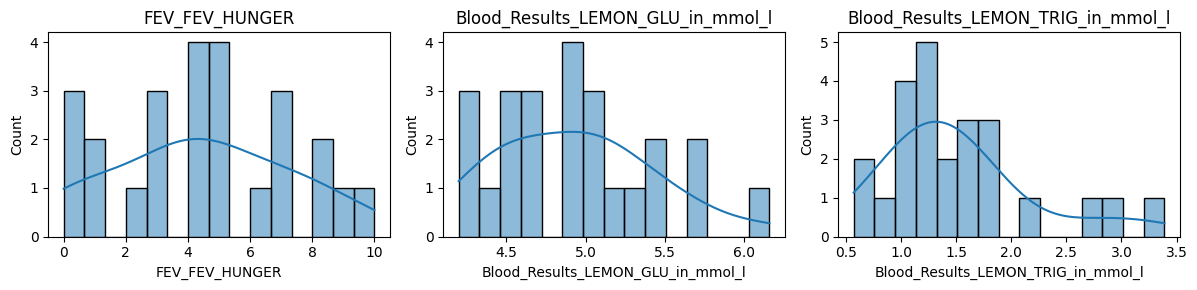

In [25]:
hunger_vars = ['FEV_FEV_HUNGER', 'Blood_Results_LEMON_GLU_in_mmol_l',
         'Blood_Results_LEMON_TRIG_in_mmol_l']

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, var in zip(axes, hunger_vars):
    sns.histplot(non_brain_fem_ob_df[var].dropna(), bins=15, kde=True, ax=ax)
    ax.set_title(var)
plt.tight_layout()
plt.show()

###### Develop hunger score 

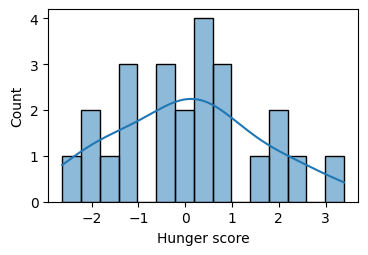

In [26]:
z = pd.DataFrame(StandardScaler().fit_transform(non_brain_fem_ob_df[hunger_vars]),
                 columns=hunger_vars, index=non_brain_fem_ob_df.index)

non_brain_fem_ob_df['hunger_score'] = z['FEV_FEV_HUNGER'] - z['Blood_Results_LEMON_GLU_in_mmol_l'] - z['Blood_Results_LEMON_TRIG_in_mmol_l']
plt.figure(figsize=(4, 2.5))
sns.histplot(non_brain_fem_ob_df['hunger_score'].dropna(), bins=15, kde=True)
plt.xlabel('Hunger score')
plt.show()

Using **cut-off**: 

In [27]:
cut_off_score=0.5

In [28]:
hunger_col= 'hunger_score'
hunger_cutoff = cut_off_score
satiety_cutoff= -cut_off_score

non_brain_fem_ob_df['Metabolic_State'] = np.select(
    [ non_brain_fem_ob_df[hunger_col] >= hunger_cutoff, non_brain_fem_ob_df[hunger_col] <= satiety_cutoff],
    [ 'Hungry/Fasting', 'Non-hungry' ], default='Intermediate' )

In [29]:
# Check participant numbers
print('Female participants:', non_brain_fem_df.shape[0])
print('Overweight/obese females:', non_brain_fem_ob_df.shape[0])
print('--------------------------------------')
print(non_brain_fem_ob_df['Metabolic_State'].value_counts())
# Check BMI distribution 
print(non_brain_fem_ob_df.groupby('Metabolic_State')['BMI'].describe())

Female participants: 73
Overweight/obese females: 25
--------------------------------------
Metabolic_State
Intermediate      9
Hungry/Fasting    9
Non-hungry        7
Name: count, dtype: int64
                 count       mean       std        min        25%        50%  \
Metabolic_State                                                                
Hungry/Fasting     9.0  28.170455  3.551427  25.478372  25.751513  27.084159   
Intermediate       9.0  29.166196  3.207753  25.699462  26.821990  28.913820   
Non-hungry         7.0  28.748337  2.394181  25.616296  26.637750  29.904306   

                       75%        max  
Metabolic_State                        
Hungry/Fasting   28.321664  36.649262  
Intermediate     29.830761  35.672120  
Non-hungry       30.320171  31.801916  


In [30]:
# Create final hunger and non-hunger df
non_brain_fem_ob_hunger_df= non_brain_fem_ob_df[non_brain_fem_ob_df['Metabolic_State'] == 'Hungry/Fasting']
non_brain_fem_ob_hunger_df=non_brain_fem_ob_hunger_df.drop(columns=['Metabolic_State'])

non_brain_fem_ob_satiety_df= non_brain_fem_ob_df[non_brain_fem_ob_df['Metabolic_State'] == 'Non-hungry']
non_brain_fem_ob_satiety_df=non_brain_fem_ob_satiety_df.drop(columns=['Metabolic_State'])


### Check overlap subjects between FC and non-brain 

In [31]:
FC_filtered_hunger_df = FC_adjusted_df.loc[FC_adjusted_df['subj_id'].isin(non_brain_fem_ob_hunger_df['ID'])].copy()
FC_filtered_satiety_df = FC_adjusted_df.loc[FC_adjusted_df['subj_id'].isin(non_brain_fem_ob_satiety_df['ID'])].copy()
print('# of overlap HUNGER subject ',FC_filtered_hunger_df.shape[0])
print('# of overlap NON-HUNGER subject ',FC_filtered_satiety_df.shape[0])
print(' ')
missing_ids_hunger = non_brain_fem_ob_hunger_df.loc[
    ~non_brain_fem_ob_hunger_df['ID'].isin(FC_adjusted_df['subj_id']), 'ID']

missing_ids_satiety = non_brain_fem_ob_satiety_df.loc[
    ~non_brain_fem_ob_satiety_df['ID'].isin(FC_adjusted_df['subj_id']), 'ID']

print('subj in hunger demo df but not have FC ',missing_ids_hunger.tolist())
print('subj in satiety demo df but not have FC ',missing_ids_satiety.tolist())

# of overlap HUNGER subject  7
# of overlap NON-HUNGER subject  4
 
subj in hunger demo df but not have FC  ['sub-010078', 'sub-010248']
subj in satiety demo df but not have FC  ['sub-010043', 'sub-010047', 'sub-010280']


# select want **hunger/satiety dfs**

In [ ]:
################### adjust cov ###################

In [69]:
################### adjust cov ###################

# Trehsholding 
20% remain within subject

In [32]:
subj_id_used=FC_filtered_hunger_df['subj_id'] #FC_adjusted_df['subj_id']

## Select want to use the FC for hungery subset or sateity subset

In [34]:
subset_fc=FC_filtered_hunger_df

In [35]:
FC_adjusted_df=subset_fc.drop(columns=['subj_id'])

In [36]:
def proportional_thresholding(X, proportion=0.20):
    X = np.asarray(X)
    X_thresholded = np.zeros_like(X)
    n_subjects, n_features = X.shape
    n_keep = int(np.ceil(n_features * proportion))
    for i in range(n_subjects):
        # Absolute FC strength
        abs_values = np.abs(X[i])
        # Indices of top 20% strongest connections
        top_indices = np.argpartition(abs_values, -n_keep )[-n_keep:]
        # Retain original signed FC values
        X_thresholded[i, top_indices] = X[i, top_indices]
    return X_thresholded

# Apply thresholding
sparse_FC_df = proportional_thresholding(FC_adjusted_df, proportion=0.20)
sparse_FC_df=pd.DataFrame( sparse_FC_df, index=FC_adjusted_df.index, columns=FC_adjusted_df.columns )

In [37]:
sparse_FC_df.shape

(7, 3828)

# Network

In [39]:
#Extract columns where column names contain any of the specified ROI numbers
def extract_roi_columns_regex(fc_df, roi_numbers): 
    # Remove 0 from the list since columns start from roi1
    roi_numbers = [roi for roi in roi_numbers if roi != 0]    
    # Create regex pattern to match roiX where X is any of the numbers
    pattern = r'roi(' + '|'.join(map(str, roi_numbers)) + r')(_|$)'
    # Filter columns that match the pattern
    matching_columns = [
        col for col in fc_df.columns 
        if re.search(pattern, col) ]
    return fc_df[matching_columns]

acc_roi_numbers=np.arange(1,89).tolist()
FC_adj_sparse_df = extract_roi_columns_regex(sparse_FC_df, acc_roi_numbers)
FC_adj_sparse_df

,roi2_roi1_delta,roi3_roi1_delta,roi3_roi2_delta,roi4_roi1_delta,roi4_roi2_delta,roi4_roi3_delta,roi5_roi1_delta,roi5_roi2_delta,roi5_roi3_delta,roi5_roi4_delta,...,roi88_roi78_delta,roi88_roi79_delta,roi88_roi80_delta,roi88_roi81_delta,roi88_roi82_delta,roi88_roi83_delta,roi88_roi84_delta,roi88_roi85_delta,roi88_roi86_delta,roi88_roi87_delta
14,0.0,0.000000,0.000000,0.00000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,...,0.00000,1.813094,1.818185,2.192232,1.870224,0.0,0.000000,0.000000,0.0,2.089223
40,0.0,0.000000,0.000000,1.11126,0.0,0.0,0.000000,0.990506,1.008419,0.959413,...,0.00000,0.000000,0.000000,0.000000,1.124476,0.0,0.000000,1.187342,0.0,1.511669
62,0.0,0.000000,0.000000,0.00000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000
96,0.0,0.000000,0.968053,0.00000,0.0,0.0,0.000000,1.058651,0.000000,0.000000,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000
108,0.0,0.000000,0.000000,0.00000,0.0,0.0,1.044293,0.000000,0.000000,0.000000,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000
144,0.0,1.065931,0.000000,0.00000,0.0,0.0,1.126426,1.362860,0.000000,0.000000,...,1.15609,1.104202,0.000000,1.224663,1.147561,0.0,1.372779,1.026532,0.0,1.180738
148,0.0,0.000000,0.000000,0.00000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,...,0.00000,0.000000,0.000000,0.000000,1.027151,0.0,0.000000,0.951267,0.0,0.000000


Check if any FC values <0 and if any nan

In [40]:
(FC_adj_sparse_df < 0).any().any()

False

In [197]:
nan_features=FC_adj_sparse_df.columns[FC_adj_sparse_df.isna().any()].tolist()
print("Feature names:", nan_features)

Feature names: []


In [43]:
from scipy.stats import zscore
import networkx as nx
def calculate_specific_roi_connectivity_sum_efficient(
    acc_fcdf, roi_list, bands=['delta', 'theta', 'alpha', 'beta', 'gamma']
):
    result_df = pd.DataFrame(index=acc_fcdf.index)

    # Calculate WDC separately for each band
    for band in bands:
        band_cols = [col for col in acc_fcdf.columns
                     if col.endswith(f'_{band}')]

        for roi in roi_list:
            roi_str = f"roi{roi}"

            # Select connections involving this ROI within this band
            roi_columns = [
                col for col in band_cols
                if roi_str in col.split('_')[:2]
            ]

            # Sum connectivity values
            if roi_columns:
                result_df[f"{roi_str}_{band}"] = (
                    acc_fcdf[roi_columns].sum(axis=1)
                )
    return result_df
    
def calculate_betweenness_centrality(
    FC_df,
    n_rois=88,
    band_mode="separate",  # "single", "separate", "combined"
    selected_band="gamma",
    bands=("delta", "theta", "alpha", "beta", "gamma")
):
    roi_names = [f"roi{i}" for i in range(1, n_rois + 1)]

    if band_mode == "single":
        bands_to_process = [selected_band]
    elif band_mode == "separate":
        bands_to_process = list(bands)
    elif band_mode == "combined":
        bands_to_process = ["combined"]
    else:
        raise ValueError("band_mode must be 'single', 'separate', or 'combined'")

    results_all = []
    for band in bands_to_process:
        if band == "combined":
            band_cols = [col for col in FC_df.columns  if any(col.endswith(f"_{b}") for b in bands)]
        else:
            band_cols = [ col for col in FC_df.columns if col.endswith(f"_{band}")]
       
        results = []
        for _, row in FC_df[band_cols].iterrows():
            G = nx.Graph()
            G.add_nodes_from(roi_names)

            # Build network
            for col, weight in row.items():
                if not np.isfinite(weight) or weight <= 0:
                    continue
                roi1, roi2 = col.split("_")[:2]
                if roi1 != roi2:
                    G.add_edge(roi1, roi2, weight=float(weight), distance=1.0 / float(weight) )

            bc = nx.betweenness_centrality( G, weight="distance", normalized=True )
            results.append(bc)

        bc_df = pd.DataFrame(results, index=FC_df.index)
        bc_df = bc_df.reindex(columns=roi_names, fill_value=0)

        suffix = band if band != "combined" else "combined"
        bc_df.columns = [f"{roi}_{suffix}" for roi in roi_names]

        results_all.append(bc_df)
    return pd.concat(results_all, axis=1)

In [44]:
# Calculate WDC for all five bands
roi_wdfc = calculate_specific_roi_connectivity_sum_efficient( FC_adj_sparse_df, acc_roi_numbers )
# Z-score each ROI-band feature across participants
roi_wdfc_std = roi_wdfc.apply(zscore, axis=0)
print(roi_wdfc_std.shape)

roi_betweenfc  = calculate_betweenness_centrality( FC_adj_sparse_df, band_mode="single", selected_band=band)
roi_betweenfc_std=roi_betweenfc.apply(zscore, axis=0)
print(roi_betweenfc_std.shape)

(7, 88)
(7, 88)


In [45]:
# Rename columns to distinguish centrality types
wdc = roi_wdfc_std.add_prefix("WDC_")
bc = roi_betweenfc_std.add_prefix("BC_")

# Concatenate all features
X_centrality = pd.concat([wdc, bc], axis=1)
print(X_centrality.shape)

(7, 176)


In [46]:
#X_centrality.head(2)
nan_features=X_centrality.columns[X_centrality.isna().any()].tolist()
print("Feature names:", nan_features)

X_centrality = X_centrality.apply(
    lambda row: row.fillna(row.mean()), axis=1
)
print(X_centrality.columns[X_centrality.isna().any()].tolist())

Feature names: []
[]


# Transfer to common space

In [47]:
internal_X=pd.read_csv('/home/yueyu91p/a_obesity_subtype_MajRev/Data/FC_age_adj/fast_wdfc_btw_sparse_age_fc_adj/delta_network.csv')

##### Umap too check similarity in distribution

Common valid features: 176


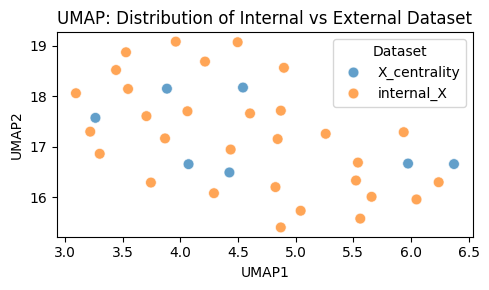

In [48]:
# Keep common features, preserving their order
common_features = X_centrality.columns.intersection(internal_X.columns)

X1 = X_centrality[common_features].copy()
X2 = internal_X[common_features].copy()

# Ensure numerical values
X1 = X1.apply(pd.to_numeric, errors='coerce')
X2 = X2.apply(pd.to_numeric, errors='coerce')

# Replace missing/infinite values
X1 = X1.replace([np.inf, -np.inf], np.nan)
X2 = X2.replace([np.inf, -np.inf], np.nan)

# Use features with no missing values in either dataset
valid_features = X1.columns[ X1.notna().all() & X2.notna().all()]

X1 = X1[valid_features]
X2 = X2[valid_features]

print("Common valid features:", len(valid_features))

# Combine datasets
X_combined = pd.concat([X1, X2], axis=0)

# Standardise combined data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_combined)

# Fit UMAP on combined data
reducer = umap.UMAP(random_state=42)
embedding = reducer.fit_transform(X_scaled)

# Separate embeddings
n1 = len(X1)

embedding_df = pd.DataFrame({
    'UMAP1': embedding[:, 0],
    'UMAP2': embedding[:, 1],
    'Dataset': ['X_centrality'] * n1 + ['internal_X'] * len(X2)
})

# Visualisation
plt.figure(figsize=(5, 3))

sns.scatterplot(
    data=embedding_df,
    x='UMAP1',
    y='UMAP2',
    hue='Dataset',
    alpha=0.7,
    s=60
)

plt.title('UMAP: Distribution of Internal vs External Dataset')
plt.legend(title='Dataset')
plt.tight_layout()
plt.show()


##### Align lemon to internal using Z_score 

In [50]:
# Ensure both datasets contain the same features in the same order
features = internal_X.columns.intersection(X_centrality.columns)

# Copy df2; keep df1 unchanged
X_centrality_aligned = X_centrality.copy()

# Reference distribution (df1)
mu1 = internal_X[features].mean()
sd1 = internal_X[features].std()

# External distribution (df2)
mu2 = X_centrality[features].mean()
sd2 = X_centrality[features].std()

# Align df2 to df1
X_centrality_aligned[features] = (
    (X_centrality[features] - mu2) / sd2
) * sd1 + mu1

print("Original internal_X shape:", internal_X.shape)
print("Original X_centrality shape:", X_centrality.shape)
print("Aligned X_centrality shape:", X_centrality_aligned.shape)

# Before alignment
mean_diff_before = ( internal_X[features].mean() - X_centrality[features].mean() ).abs().mean()

sd_diff_before = ( internal_X[features].std() - X_centrality[features].std() ).abs().mean()

# After alignment
mean_diff_after = ( internal_X[features].mean() - X_centrality_aligned[features].mean()).abs().mean()

sd_diff_after = ( internal_X[features].std() - X_centrality_aligned[features].std() ).abs().mean()

# Summary
print(f"Mean difference before alignment: {mean_diff_before:.6f}")
print(f"Mean difference after alignment:  {mean_diff_after:.6f}")

print(f"SD difference before alignment:   {sd_diff_before:.6f}")
print(f"SD difference after alignment:    {sd_diff_after:.6f}")

Original internal_X shape: (30, 176)
Original X_centrality shape: (7, 176)
Aligned X_centrality shape: (7, 176)
Mean difference before alignment: 0.000000
Mean difference after alignment:  0.000000
SD difference before alignment:   0.063028
SD difference after alignment:    0.000000


# Transfer RSKC

In [52]:
band_meta='delta_fasting'

In [53]:
rskc_dir = ("/home/yueyu91p/a_obesity_subtype_MajRev/Results/RSKC_models")

# Load cluster labels
inter_cluster_df = pd.read_csv(os.path.join(rskc_dir, f"{band_meta}_cluster_labels.csv"))
# Load feature weights
inter_weights_df = pd.read_csv(os.path.join(rskc_dir, f"{band_meta}_RSKC_feature_weights.csv"))
# Load cluster centroids
inter_centroids_df = pd.read_csv(os.path.join(rskc_dir, f"{band_meta}_RSKC_cluster_centroids.csv"),index_col=0)
# Load feature names
inter_feature_names = pd.read_csv(os.path.join(rskc_dir, f"{band_meta}_RSKC_feature_names.csv"))["Feature"].tolist()
# Load model parameters
inter_parameters_df = pd.read_csv(os.path.join(rskc_dir,f"{band_meta}_RSKC_parameters.csv"))
# Extract arrays
weights = inter_weights_df["Weight"].to_numpy()
centroids = inter_centroids_df.to_numpy()
inter_cluster_labels = inter_cluster_df["Cluster"].to_numpy()
print("Number of features:", len(inter_feature_names))
print("Number of weights:", len(weights))
print("Centroid dimensions:", centroids.shape)
print("Cluster distribution:", pd.Series(inter_cluster_labels).value_counts())

Number of features: 176
Number of weights: 176
Centroid dimensions: (2, 176)
Cluster distribution: 2    26
1     4
Name: count, dtype: int64


In [85]:
#cluster_df

In [54]:
X_external = X_centrality_aligned
print (X_external.shape[1] == len(inter_feature_names))

True


In [55]:
# Calculate weighted squared Euclidean distance
def weighted_distance(X, centroid, weights):
    return np.sum(
        weights * (X - centroid) ** 2,axis=1 )
    
# Calculate distances to each original cluster
distance_matrix = np.column_stack([
    weighted_distance( X_external,centroids[k, :], weights)
    for k in range(len(centroids))
])
# Assign to nearest cluster
external_labels = np.argmin(distance_matrix, axis=1) + 1
# Create results
validation_results = pd.DataFrame({
    "Subject_ID": subj_id_used,
    "Assigned_Cluster": external_labels,
    "Distance_Cluster1": distance_matrix[:, 0],
    "Distance_Cluster2": distance_matrix[:, 1]
})
print(validation_results)
print("\nExternal cluster distribution:")
print(validation_results["Assigned_Cluster"].value_counts())


     Subject_ID  Assigned_Cluster  Distance_Cluster1  Distance_Cluster2
14   sub-010166                 2           7.293388           4.953063
40   sub-010168                 2          23.461519           0.887396
62   sub-010165                 2          16.246791           2.287719
96   sub-010004                 2          16.335919           0.313401
108  sub-010222                 2          19.074742           0.385847
144  sub-010048                 2           5.902987           3.104322
148  sub-010064                 2           8.860466           2.487717

External cluster distribution:
Assigned_Cluster
2    7
Name: count, dtype: int64


##### Confirm if cluster 1 and 2 consistenly refer to 1 and 2 between internal and lemon
Should match if consistenty (means the cluster id of FC in internal data is consistent with the centroid id read by lemon)

In [61]:
# Calculate original internal cluster means
internal_cluster_means = internal_X.copy()
internal_cluster_means["Cluster"] = inter_cluster_labels
internal_cluster_means = ( internal_cluster_means.groupby("Cluster")[inter_feature_names].mean())
internal_cluster_means

,WDC_roi1_delta,WDC_roi2_delta,WDC_roi3_delta,WDC_roi4_delta,WDC_roi5_delta,WDC_roi6_delta,WDC_roi7_delta,WDC_roi8_delta,WDC_roi9_delta,WDC_roi10_delta,...,BC_roi79_delta,BC_roi80_delta,BC_roi81_delta,BC_roi82_delta,BC_roi83_delta,BC_roi84_delta,BC_roi85_delta,BC_roi86_delta,BC_roi87_delta,BC_roi88_delta
Cluster,,,,,,,,,,,,,,,,,,,,,
1,1.072567,-0.373590,1.015068,-0.325256,0.662168,-0.593013,1.033215,-0.587613,0.306859,0.322312,...,-0.639213,-0.331061,-0.616205,-0.659757,-0.418414,-0.903853,-0.646907,-0.118186,-0.434694,-0.626459
2,-0.165010,0.057475,-0.156164,0.050039,-0.101872,0.091233,-0.158956,0.090402,-0.047209,-0.049587,...,0.098340,0.050932,0.094801,0.101501,0.064371,0.139054,0.099524,0.018182,0.066876,0.096378


In [62]:
pd.DataFrame(centroids,columns=inter_feature_names)


Saved RSKC centroids:


,WDC_roi1_delta,WDC_roi2_delta,WDC_roi3_delta,WDC_roi4_delta,WDC_roi5_delta,WDC_roi6_delta,WDC_roi7_delta,WDC_roi8_delta,WDC_roi9_delta,WDC_roi10_delta,...,BC_roi79_delta,BC_roi80_delta,BC_roi81_delta,BC_roi82_delta,BC_roi83_delta,BC_roi84_delta,BC_roi85_delta,BC_roi86_delta,BC_roi87_delta,BC_roi88_delta
0,1.072567,-0.373590,1.015068,-0.325256,0.662168,-0.593013,1.033215,-0.587613,0.306859,0.322312,...,-0.639213,-0.331061,-0.616205,-0.659757,-0.418414,-0.903853,-0.646907,-0.118186,-0.434694,-0.626459
1,-0.165010,0.057475,-0.156164,0.050039,-0.101872,0.091233,-0.158956,0.090402,-0.047209,-0.049587,...,0.098340,0.050932,0.094801,0.101501,0.064371,0.139054,0.099524,0.018182,0.066876,0.096378


## Select clinical variables that relevant to the significant variables from Internal data

In [57]:
variables = ['YFAS_YFAS_symptom_count', 'BISBAS_BAS_Drive', 'FEV_FEV_STOER', 'FEV_FEV_KK','CERQ_CERQ_Rumination']

In [58]:
dfext = pd.DataFrame({'subid': subj_id_used})


matched = dfext[['subid']].merge(
    non_brain_data[['ID'] + variables],
    left_on='subid', right_on='ID', how='inner'
)

# Z-transform each variable before calculating means
matched[variables] = matched[variables].apply(
    lambda x: (pd.to_numeric(x, errors='coerce') - 
               pd.to_numeric(x, errors='coerce').mean()) /
              pd.to_numeric(x, errors='coerce').std()
)

# Calculate means
cluster_means = matched[variables].mean().to_frame('Mean_Z_score')

print(cluster_means)

                         Mean_Z_score
YFAS_YFAS_symptom_count  0.000000e+00
BISBAS_BAS_Drive         8.326673e-17
FEV_FEV_STOER           -1.665335e-16
FEV_FEV_KK               0.000000e+00
CERQ_CERQ_Rumination     3.013462e-16


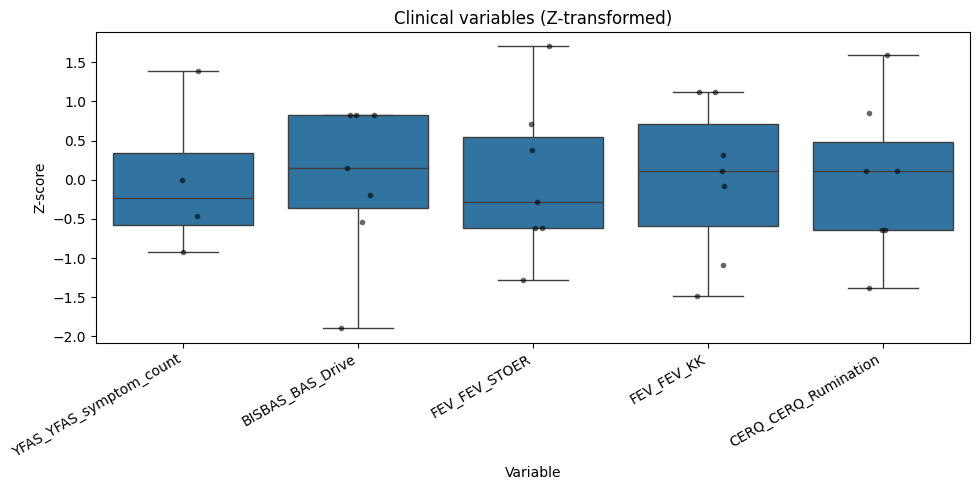

In [59]:
plot_df = matched[variables].melt(var_name='Variable', value_name='Z-score')

plt.figure(figsize=(10, 5))
sns.boxplot(data=plot_df, x='Variable', y='Z-score', showfliers=False)
sns.stripplot(data=plot_df, x='Variable', y='Z-score',
              color='black', alpha=0.6, jitter=True, size=4)

plt.xticks(rotation=30, ha='right')
plt.title('Clinical variables (Z-transformed)')
plt.tight_layout()
plt.show()

FEV_FEV_STOER    DEBQ External eating, same dir
FEV_FEV_KK        DEBQ restrained eating, same dir
CERQ_             DEBQ Emotional eating

In [63]:
band='delta' 
met_state='fast'

In [64]:
# Load internal data
internal_path = (
    f"/home/yueyu91p/a_obesity_subtype_MajRev/Results/"
    f"Sig_clinicvar_internal/{band}_significant_variables_{met_state}.csv"
)
internal_df = pd.read_csv(internal_path)

# Variable correspondence: external, internal
variable_pairs = {
    'YFAS symptom count': ('YFAS_YFAS_symptom_count', 'YFAS_SYMP'),
    'BAS Drive': ('BISBAS_BAS_Drive', 'BISBAS_BASDRIVE'),
    'Eating disinhibition': ('FEV_FEV_STOER', 'DEB_EX'),
    'Eating restraint': ('FEV_FEV_KK', 'DEB_R'),
    'Eating emotional': ('CERQ_CERQ_Rumination', 'DEB_EM')
}


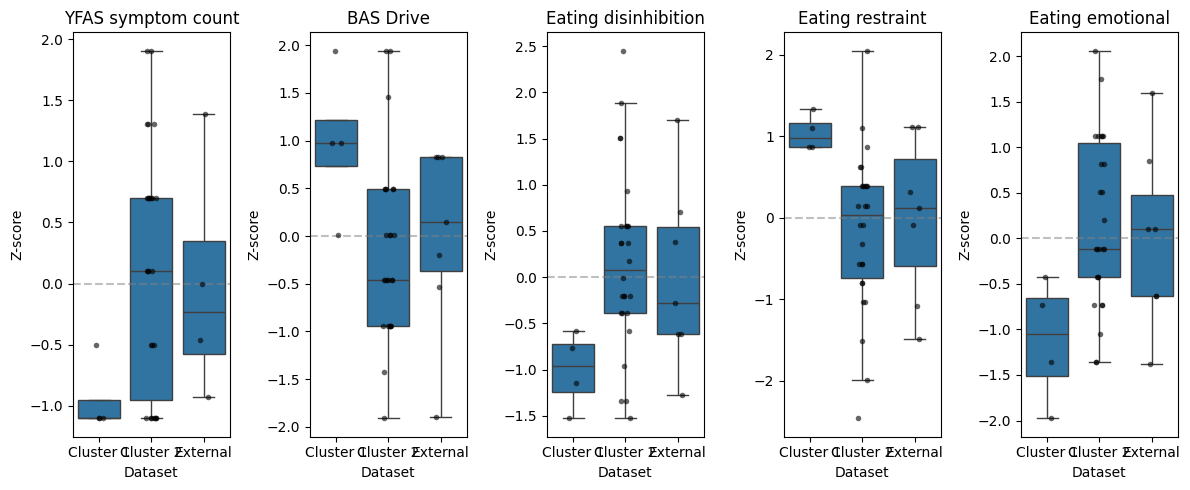

               Variable  Cluster  Mean_difference
3             BAS Drive        2         0.150694
2             BAS Drive        1         0.979514
5  Eating disinhibition        2         0.154973
4  Eating disinhibition        1         1.007323
9      Eating emotional        2         0.172717
8      Eating emotional        1         1.122660
7      Eating restraint        2         0.160030
6      Eating restraint        1         1.040193
1    YFAS symptom count        2         0.146508
0    YFAS symptom count        1         0.952301


In [68]:
plot_data, similarity_results = [], []

for name, (ext_var, int_var) in variable_pairs.items():

    int_values = pd.to_numeric(internal_df[int_var], errors='coerce')
    ext_values = pd.to_numeric(matched[ext_var], errors='coerce')

    # Independently Z-transform both datasets
    internal_z = (int_values - int_values.mean()) / int_values.std()
    external_z = (ext_values - ext_values.mean()) / ext_values.std()

    for cluster in sorted(internal_df['Cluster'].dropna().unique()):
        cluster_z = internal_z[internal_df['Cluster'] == cluster].dropna()

        plot_data.extend([
            {'Variable': name, 'Dataset': f'Cluster {cluster}', 'Z-score': v}
            for v in cluster_z
        ])

        similarity_results.append({
            'Variable': name,
            'Cluster': cluster,
            'Mean_difference': abs(external_z.mean() - cluster_z.mean())
        })

    plot_data.extend([
        {'Variable': name, 'Dataset': 'External', 'Z-score': v}
        for v in external_z.dropna()
    ])

plot_df = pd.DataFrame(plot_data)

# Plot
fig, axes = plt.subplots(1, 5, figsize=(12, 5))

for ax, name in zip(axes.flatten(), variable_pairs):
    subset = plot_df[plot_df['Variable'] == name]

    sns.boxplot(data=subset, x='Dataset', y='Z-score',
                ax=ax, showfliers=False)
    sns.stripplot(data=subset, x='Dataset', y='Z-score',
                  ax=ax, color='black', alpha=0.6,
                  jitter=True, size=4)

    ax.set_title(name)
    ax.axhline(0, ls='--', color='grey', alpha=0.5)

plt.tight_layout()
plt.show()

# Mean differences
similarity_df = pd.DataFrame(similarity_results)
print(similarity_df.sort_values(['Variable', 'Mean_difference']))

In [ ]:
######################################### Below not used  #######################

**band and metabolic state**

In [102]:
delta_hunger_df=non_brain_ob_hunger_df[non_brain_ob_hunger_df["ID"].isin(validation_results["Subject_ID"])].reset_index(drop=True)
delta_hunger_df['cluster_id']=validation_results['Assigned_Cluster']
features = delta_hunger_df.columns.drop(['ID','cluster_id']).tolist()

In [105]:
data_for_test =delta_hunger_df

significant_features = []          # <-- collect features with p < 0.05

for feature in features:
    data = data_for_test[[feature, 'cluster_id']].dropna()

    cluster_ids = sorted(data['cluster_id'].unique())
    groups = [data.loc[data['cluster_id'] == c, feature] for c in cluster_ids]

    if len(groups) < 2:
        print(f"\n{feature}: not enough clusters, skipping")
        continue

    H, p = kruskal(*groups)
    print(f"\n{feature}")
    print(f"Kruskal-Wallis H = {H:.3f}, p = {p:.4f}  (clusters: {cluster_ids})")

    if p < 0.05:
        significant_features.append(feature)        # <-- add here
        dunn = sp.posthoc_dunn(
            data,
            val_col=feature,
            group_col='cluster_id',
            p_adjust="holm"
        )
        print("Dunn-Holm (adjustment family = pairwise cluster comparisons):")
        print(dunn)

print("\n=== Significant features (Kruskal-Wallis p < 0.05) === ")
print(significant_features)

print (f'************ Significant varibles BEFORE Multiple Comparison ***********')
print(significant_features)


Blood_Results_LEMON_ALAT_in_ µkat_l: not enough clusters, skipping

Blood_Results_LEMON_ASAT_in_µkat_l: not enough clusters, skipping

Blood_Results_LEMON_CHOL_in_mmol_l: not enough clusters, skipping

Blood_Results_LEMON_GGT_in_µkat_l: not enough clusters, skipping

Blood_Results_LEMON_GLU_in_mmol_l: not enough clusters, skipping

Blood_Results_LEMON_HBA1C_in_%: not enough clusters, skipping

Blood_Results_LEMON_HBA1CI_in_mmol_mol: not enough clusters, skipping

Blood_Results_LEMON_HDLC_in_mmol_l: not enough clusters, skipping

Blood_Results_LEMON_LDLC_in_mmol_l: not enough clusters, skipping

Blood_Results_LEMON_TRIG_in_mmol_l: not enough clusters, skipping

Blood_Results_LEMON_TSH_in_mU_l: not enough clusters, skipping

Blood_Results_LEMON_WBC_in_exp_9_l: not enough clusters, skipping

Blood_Results_LEMON_PLT_in_exp_9 _l: not enough clusters, skipping

Blood_Results_LEMON_MPV_in_fl: not enough clusters, skipping

Blood_Results_LEMON_RDW_in_%: not enough clusters, skipping

Blood_Re

In [103]:
data_for_test = delta_hunger_df

# Calculate mean of each feature by cluster
cluster_means = data_for_test.groupby('cluster_id')[features].mean().T

# Rename columns
cluster_means.columns = [
    f'Cluster_{c}_Mean' for c in cluster_means.columns
]

# Display results
print(cluster_means)

# Save to CSV
#cluster_means.to_csv(
 #   f"{band_meta}_Dataset2_cluster_means.csv"
#)

                                     Cluster_2_Mean
Blood_Results_LEMON_ALAT_in_ µkat_l        0.468667
Blood_Results_LEMON_ASAT_in_µkat_l         0.417333
Blood_Results_LEMON_CHOL_in_mmol_l         4.976000
Blood_Results_LEMON_GGT_in_µkat_l          0.367333
Blood_Results_LEMON_GLU_in_mmol_l          4.847333
...                                             ...
MSPSS_MSPSS_SignificantOthers             23.933333
MSPSS_MSPSS_Family                        22.866667
MSPSS_MSPSS_Friends                       23.133333
MSPSS_MSPSS_total                         69.933333
BMI                                       28.522342

[143 rows x 1 columns]


In [104]:
# Mean difference: Cluster 2 - Cluster 1
mean_diff = (
    cluster_means['Cluster_2_Mean'] -
    cluster_means['Cluster_1_Mean']
)

# Select top 10 variables by absolute mean difference
top10_diff = mean_diff.loc[
    mean_diff.abs().nlargest(20).index
].sort_values()

# Plot
plt.figure(figsize=(10, 6))

colors = [
    'steelblue' if x > 0 else 'indianred'
    for x in top10_diff
]

plt.barh(
    top10_diff.index,
    top10_diff.values,
    color=colors
)

plt.axvline(0, color='black', linewidth=0.8)

plt.xlabel('Mean Difference (Cluster 2 - Cluster 1)')
plt.ylabel('Variables')
plt.title('Top 10 Variables with Largest Mean Differences')

plt.tight_layout()
plt.show()

KeyError: 'Cluster_1_Mean'

# < up to here >

######################################## Old

compute weighted degree connectivity (i.e. strength)

In [7]:
def calculate_specific_roi_connectivity_sum_efficient(acc_fcdf, roi_list):
    # Convert ROI numbers to the format used in column names
    roi_strings = [f"roi{roi}" for roi in roi_list]
    # Create empty result dataframe
    result_df = pd.DataFrame(0, index=acc_fcdf.index, columns=roi_strings)
    # Pre-process column information
    column_info = []
    for col in acc_fcdf.columns:
        parts = col.split('_')
        roi1, roi2 = parts[0], parts[1]
        column_info.append((roi1, roi2, col))
    # For each target ROI, sum all connections involving it
    for roi in roi_strings:
        # Find all columns where this ROI appears
        roi_columns = []
        for roi1, roi2, col_name in column_info:
            if roi1 == roi or roi2 == roi: ########### Self-connection excluded , Symmetrical pair only cont one of the unique #################
                roi_columns.append(col_name) 
        # Sum all connections involving this ROI
        if roi_columns:
            result_df[roi] = acc_fcdf[roi_columns].sum(axis=1)  
    return result_df

roi_wdfc = calculate_specific_roi_connectivity_sum_efficient(FC_df, acc_roi_numbers)
from scipy.stats import zscore
roi_wdfc_std = (roi_wdfc).apply(zscore)


In [8]:
np.array(roi_wdfc_std)

array([[-0.02106319, -0.01356329, -0.02717629, ..., -0.04886974,
        -0.07128915, -0.0679368 ],
       [-0.29883869, -0.13312926, -0.42791788, ..., -0.21150104,
        -0.10528393, -0.25692477],
       [-0.24869875, -0.21482261, -0.23284974, ..., -0.21951718,
        -0.27966849, -0.19724982],
       ...,
       [-0.34612901, -0.26474931, -0.3057151 , ..., -0.17615239,
        -0.27048854, -0.15476492],
       [-0.31811296, -0.14294619, -0.27047675, ..., -0.19422774,
        -0.12302156, -0.23484148],
       [-0.16536815, -0.0958082 , -0.1256138 , ..., -0.08002796,
        -0.09998867, -0.12725212]], shape=(195, 88))

### Project LEMON into original obesity UMAP space

In [187]:
metabolic_state='Fasting'#'Satiety'

In [188]:
import joblib

umap_ob = joblib.load(f"/home/yueyu91p/Internal_UMAP_Output_Models/{metabolic_state}/obese_T0_umap_model_{band}.pkl")

# Project LEMON into your original obesity UMAP space
lemon_embedding = umap_ob.transform( np.array(roi_wdfc_std))

### K-mean

In [189]:
n_clusters=2

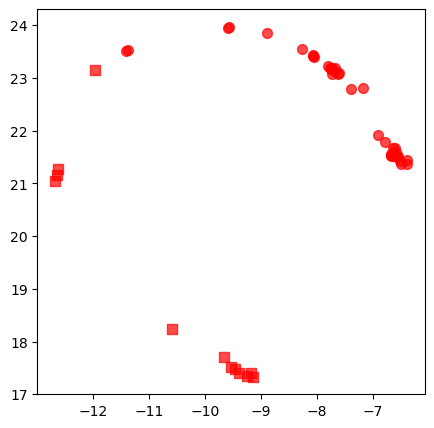

In [190]:
kmeans_mod= KMeans(n_clusters=n_clusters, random_state=42)
lemon_clusters=kmeans_mod.fit_predict(lemon_embedding)

fig, ax = plt.subplots(1, 1, figsize=(5, 5))
markers = ['o', 's', '^', 'D', 'v', '<', '>', 'p', '*', 'h', 'H', '+', 'x', 'X', 'd']
group_name='delta'

for cluster_id in range(n_clusters):
    cluster_mask = lemon_clusters == cluster_id
    if np.any(cluster_mask):
                    ax.scatter(lemon_embedding[cluster_mask, 0], 
                      lemon_embedding[cluster_mask, 1],
                      c='red', marker=markers[cluster_id % len(markers)],
                      label=f'{group_name} - Cluster {cluster_id}',
                      alpha=0.7, s=50)

In [191]:
cluster_df['Umap_embedding_0']=lemon_embedding[:,0]
cluster_df['Umap_embedding_1']=lemon_embedding[:,1]
cluster_df['Kmean_cluster_id']=lemon_clusters
cluster_df.head(2)

,subj_id,Umap_embedding_0,Umap_embedding_1,Kmean_cluster_id
0,sub-010086,-6.649118,21.548418,0
1,sub-010273,-9.462761,17.472034,1


#### Compare Non-brain Data between clusters

In [ ]:
non_brain_data = pd.read_csv('/home/yueyu91p/all_non_brain_data_preprocessed.csv')
non_brain_data_50 = non_brain_data[non_brain_data["ID"].isin(cluster_df["subj_id"])].reset_index(drop=True)
non_brain_data_50['Kmean_cluster_id'] = cluster_df['Kmean_cluster_id']

features = non_brain_data_50.columns.drop(['ID','Kmean_cluster_id']).tolist()

In [ ]:
data_for_test = non_brain_data_50

significant_features = []          # <-- collect features with p < 0.05

for feature in features:
    data = data_for_test[[feature, "Kmean_cluster_id"]].dropna()

    cluster_ids = sorted(data["Kmean_cluster_id"].unique())
    groups = [data.loc[data["Kmean_cluster_id"] == c, feature] for c in cluster_ids]

    if len(groups) < 2:
        print(f"\n{feature}: not enough clusters, skipping")
        continue

    H, p = kruskal(*groups)
    print(f"\n{feature}")
    print(f"Kruskal-Wallis H = {H:.3f}, p = {p:.4f}  (clusters: {cluster_ids})")

    if p < 0.05:
        significant_features.append(feature)        # <-- add here
        dunn = sp.posthoc_dunn(
            data,
            val_col=feature,
            group_col="Kmean_cluster_id",
            p_adjust="holm"
        )
        print("Dunn-Holm (adjustment family = pairwise cluster comparisons):")
        print(dunn)

print("\n=== Significant features (Kruskal-Wallis p < 0.05) === ")
print(significant_features)


In [ ]:
print (f'************ Significant varibles BEFORE Multiple Comparison ***********')
print(significant_features)

In [ ]:
# -------------------------------------------------------
# Plot all significant features
# -------------------------------------------------------

n_features = len(significant_features)

if n_features == 0:
    print("No significant features to plot.")

else:
    # Layout
    ncols = 3
    nrows = int(np.ceil(n_features / ncols))

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(5 * ncols, 4.5 * nrows)
    )

    axes = np.array(axes).reshape(-1)

    for ax, feature in zip(axes, significant_features):

        data = data_for_test[
            [feature, "Kmean_cluster_id"]
        ].dropna()

        cluster_ids = sorted(data["Kmean_cluster_id"].unique())

        # -----------------------------
        # Boxplot
        # -----------------------------
        sns.boxplot(
            data=data,
            x="Kmean_cluster_id",
            y=feature,
            order=cluster_ids,
            ax=ax,
            showfliers=False
        )

        # Optional: show individual subjects
        sns.stripplot(
            data=data,
            x="Kmean_cluster_id",
            y=feature,
            order=cluster_ids,
            ax=ax,
            color="black",
            alpha=0.5,
            size=3,
            jitter=True
        )

        # -----------------------------
        # Dunn-Holm post-hoc test
        # -----------------------------
        dunn = sp.posthoc_dunn(
            data,
            val_col=feature,
            group_col="Kmean_cluster_id",
            p_adjust="holm"
        )

        # Find significant pairwise comparisons
        significant_pairs = []

        for i in range(len(cluster_ids)):
            for j in range(i + 1, len(cluster_ids)):

                c1 = cluster_ids[i]
                c2 = cluster_ids[j]

                p = dunn.loc[c1, c2]

                if p < 0.05:
                    significant_pairs.append((i, j, p))

        # -----------------------------
        # Add significance brackets
        # -----------------------------
        if significant_pairs:

            y_min = data[feature].min()
            y_max = data[feature].max()
            y_range = y_max - y_min

            if y_range == 0:
                y_range = 1

            base_y = y_max + 0.08 * y_range
            step = 0.12 * y_range

            for k, (i, j, p) in enumerate(significant_pairs):

                y = base_y + k * step
                h = 0.025 * y_range

                # bracket
                ax.plot(
                    [i, i, j, j],
                    [y, y + h, y + h, y],
                    c="black",
                    linewidth=1
                )

                # significance stars
                if p < 0.001:
                    stars = "***"
                elif p < 0.01:
                    stars = "**"
                else:
                    stars = "*"

                ax.text(
                    (i + j) / 2,
                    y + h,
                    stars,
                    ha="center",
                    va="bottom",
                    fontsize=12
                )

            # Increase ylim so annotations aren't cut off
            ax.set_ylim(
                y_min - 0.05 * y_range,
                base_y + len(significant_pairs) * step + 0.08 * y_range
            )

        # -----------------------------
        # Formatting
        # -----------------------------
        ax.set_title(feature)
        ax.set_xlabel("K-means cluster")
        ax.set_ylabel(feature)

    # Remove unused panels
    for ax in axes[n_features:]:
        ax.remove()
    plt.tight_layout()

    # Save the entire figure containing all subplots
    fig.savefig(
        f"/home/yueyu91p/Lemon_data_50/Lemon_50_cluster_compare_results/Satiety/significant_features_boxplots_{band}.pdf",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

### Test code to do sample test using BISBAS